# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [ ]:
import re
import numpy as np
import pandas as pd
import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns

В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [ ]:
from itertools import combinations

df = pd.read_csv("monster_com_job_sample.csv", dtype="string", keep_default_na=False)
df = df.replace(r"^\s*$", pd.NA, regex=True)
original_cols = df.columns.tolist()

print(df.shape)
display(df.sample(5, random_state=42))

(22000, 14)


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,<NA>,No,jobs.monster.com,The QC Lead position requires an understanding...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lea...,<NA>,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,<NA>,No,jobs.monster.com,JOB DESCRIPTION ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Su...,<NA>,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,<NA>,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundati...,<NA>,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,<NA>,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Ground...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",<NA>,http://jobview.monster.com/Groundskeeper-Job-K...,<NA>,<NA>,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,<NA>,No,jobs.monster.com,Combined Insurance is seeking Sales Agents to ...,Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Kno...,<NA>,<NA>,ec59e3f419b851259632b757183d7365


**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.


| Столбец | Тип после загрузки | Что видно в данных |
|---|---|---|
| `country` | string | Во всех строках одна страна |
| `country_code` | string | Во всех строках код `US` |
| `date_added` | string | Дата записана текстом, почти везде пропущена |
| `has_expired` | string | Во всех строках `No` |
| `job_board` | string | Во всех строках один сайт |
| `job_description` | string | Описания повторяются, встречаются склеенные слова |
| `job_title` | string | В название включён город, встречается значение `Monster` |
| `job_type` | string | Разные разделители, неполные записи и пропуски |
| `location` | string | Разные форматы адреса, встречаются телефоны и тексты вакансий |
| `organization` | string | Встречаются отрасли вместо компаний, есть пропуски |
| `page_url` | string | Уникальные ссылки с параметрами запроса |
| `salary` | string | Пропуски, диапазоны, разные периоды оплаты, текст о льготах |
| `sector` | string | Встречаются уровни опыта вместо отрасли, есть пропуски |
| `uniq_id` | string | Идентификатор записи, пропусков и повторов нет |

### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью столбчатой диаграммы. Для удобства можно воспользоваться модулем `missingno`.


,Всего ячеек,Пустых ячеек
country,22000,0
country_code,22000,0
date_added,22000,21878
has_expired,22000,0
job_board,22000,0
job_description,22000,0
job_title,22000,0
job_type,22000,1628
location,22000,0
organization,22000,6867


Строк с более чем 75% пропусков: 0


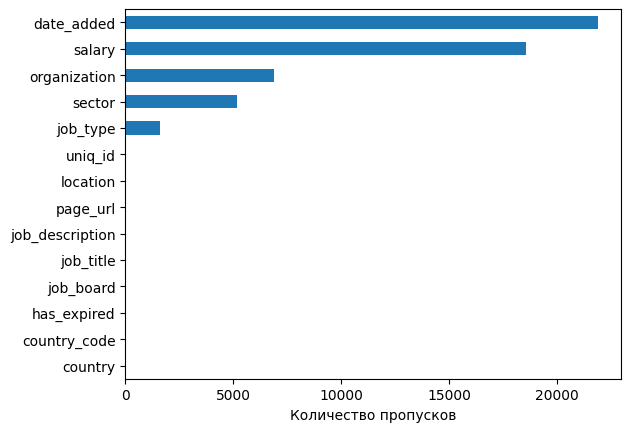

In [ ]:
missing = df[original_cols].isna()
report = pd.DataFrame({"Всего ячеек": len(df), "Пустых ячеек": missing.sum()})
display(report)
print("Строк с более чем 75% пропусков:", (missing.mean(axis=1) > 0.75).sum())
report["Пустых ячеек"].sort_values().plot.barh(xlabel="Количество пропусков")
plt.show()

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [ ]:
print("До удаления:", df[original_cols].shape)
print("После удаления:", df[original_cols].dropna().shape)

До удаления: (22000, 14)
После удаления: (5, 14)


После удаления строк, где есть пустые значения, данных для анализа практически совсем не остается. Поэтому просто удалять такие строки не вариант, можно просто для каждого расчета отбирать строки, где заполнены нужные поля.

### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [ ]:
values = {col: set(df[col].dropna()) for col in original_cols}
for col, items in values.items():
    if len(items) == 1:
        print("Постоянный столбец:", col, items)

for a, b in combinations(original_cols, 2):
    common = values[a] & values[b]
    if common:
        print(a, b, len(common), min(common, key=len)[:80])

for col in ["organization", "sector"]:
    display(df[col].value_counts().head())

Постоянный столбец: country {'United States of America'}
Постоянный столбец: country_code {'US'}
Постоянный столбец: has_expired {'No'}
Постоянный столбец: job_board {'jobs.monster.com'}
job_description job_title 1 Please apply only if you are qualified.
job_description location 849 Job Description Job #:  671297Please email resumes to cpotter@apexsystemsinc.com
job_title location 12 Recruiter
job_type location 1 Full Time Employee
job_type organization 1 Full Time Employee
location organization 126 Omaha, NE
organization sector 2 Retail


,count
organization,
Healthcare Services,1919
All,1158
Retail,1081
Other/Not Classified,1048
Manufacturing - Other,885


,count
sector,
Experienced (Non-Manager),4594
Medical/Health,1254
Entry Level,1172
Sales/Retail/Business Development,938
Manager (Manager/Supervisor of Staff),900


В датасете есть 4 стоблца, в которых встречаются одни и те же значения, для анализа по вакансиям их можно исключить.

### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [ ]:
unique_cols = [col for col in original_cols if df[col].nunique() == len(df)]
compare_cols = [col for col in original_cols if col not in unique_cols]
print("Все uniq_id различны:", df["uniq_id"].is_unique)
print("Столбцы без повторов:", unique_cols)
print("Повторных строк:", df.duplicated(compare_cols).sum())

Все uniq_id различны: True
Столбцы без повторов: ['page_url', 'uniq_id']
Повторных строк: 1168


Действительно все айдишники уникальны, как и ссылки на страницы с вакансиями. Однако найдено 1168 повторных строк, что значит, что разные айдишники мгут соответствовать записям с одинаковым содержимым.

# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

,count
location,
city + state + zip,11333
city + state,7183
не распознано,2652
city + zip,311
zip,254
state,230
state + zip,21
city,11
state + city,5


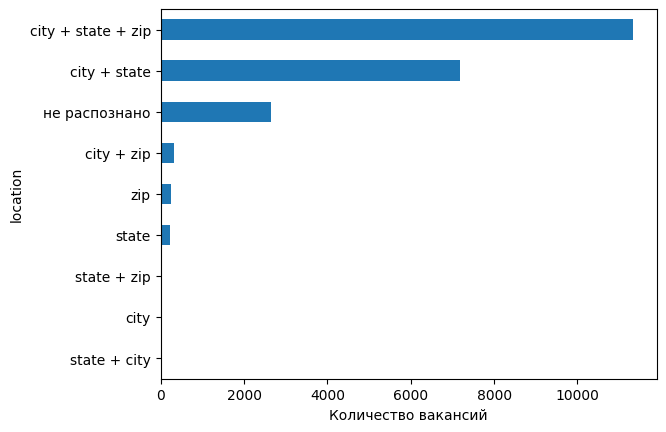

In [ ]:
location = df["location"].fillna("").str.split().str.join(" ")
fields = ["city", "state", "zip"]
codes = "AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY PR"
C = r"(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ.'’ -]{0,55}?)"
S = "(?P<state>(?i:" + "|".join(codes.split()) + "))"
Z = r"(?P<zip>\d{5}(?:-\d{4})?)"
sep, comma = r"(?:\s*,\s*|\s+)", r"\s*,\s*"
patterns = [C+sep+S+sep+Z, S+comma+C+sep+Z, S+comma+C, C+sep+S, S+sep+Z, C+sep+Z, S, Z]
known = set(location.str.extract(rf"^{C}{sep}{S}(?:{sep}{Z})?$")["city"].dropna().str.casefold())

def parse(text):
    if re.match(r"(?i)^(address|phone|fax|contact|location)\b", text):
        return {}
    for pattern in patterns:
        match = re.fullmatch(pattern, text)
        if match:
            return match.groupdict()
    return {"city": text} if text.casefold() in known else {}

records = location.map(parse)
geo = pd.DataFrame(records.tolist(), index=df.index, columns=fields)
geo["state"] = geo["state"].str.upper()
counts = records.map(lambda row: " + ".join(row) or "не распознано").value_counts()
display(counts)
counts.sort_values().plot.barh(xlabel="Количество вакансий")
plt.show()

Самый частый формат - стандартный город + штат + индекс, следом за ним город + штат. В 2652 строках формат с первого раза определить не удалось.

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [ ]:
df[fields] = geo.astype("string")
unknown = df.loc[geo.isna().all(axis=1)].copy()
display(df[["location", *fields]].head())
print("Отложено строк:", len(unknown))
display(unknown[["location"]].sample(5, random_state=42))

,location,city,state,zip
0,"Madison, WI 53702",Madison,WI,53702
1,"Madison, WI 53708",Madison,WI,53708
2,DePuy Synthes Companies is a member of Johnson...,<NA>,<NA>,<NA>
3,"Dixon, CA",Dixon,CA,<NA>
4,"Camphill, PA",Camphill,PA,<NA>


Отложено строк: 2652


,location
20457,Contact name Sarah McKernan Phone 0 Fax 0 Addr...
1489,Contact name Monica Bergstrom
9053,Location:
16135,"Phone 7818285001 Address 293 REVERE STCANTON, ..."
8687,« back Learn More Technical Support Analyst I ...


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [ ]:
names = "California|Ohio|Louisiana|Maine|Georgia|Mississippi|North Carolina|North Dakota|Oregon|Kansas|Michigan|South Carolina|Tennessee|Colorado|Nevada|Montana|Idaho|Missouri|Alabama|Illinois|Pennsylvania|Texas"
abbr = dict(zip(names.split("|"), "CA OH LA ME GA MS NC ND OR KS MI SC TN CO NV MT ID MO AL IL PA TX".split()))
towns = geo.dropna(subset=["city", "state"]).groupby("state")["city"].agg(
    lambda s: sorted(set(s), key=len, reverse=True))

def recover(text):
    m = re.search(rf"Location:\s*{C},\s*({names}),\s*United States(?:\s+ZIP Code:\s*{Z})?", text, re.I)
    if m:
        return {"city": m["city"], "state": abbr[m[2].title()], "zip": m["zip"]}
    tail = re.split(r"\bAddress\s*:?\s*|\bLocation:\s*", text, flags=re.I)[-1].strip()
    result = parse(tail)
    if result:
        return result
    m = re.search(rf",\s*{S}(?:\s+(?P<zip>\d{{5}}(?:-?\d{{4}})?))?$", tail)
    if m:
        st = m["state"].upper()
        prefix = tail[:m.start()].casefold()
        town = next((c for c in towns.get(st, []) if prefix.endswith(c.casefold())), None)
        return {"city": town, "state": st, "zip": m["zip"]}
    m = re.search(rf"\bZIP(?: Code)?\s*:\s*{Z}\b", text, re.I)
    return m.groupdict() if m else {}

rows = location.loc[unknown.index].map(recover)
fixed = pd.DataFrame(rows.tolist(), index=unknown.index, columns=fields, dtype="string")
fixed["state"] = fixed["state"].str.upper()
df.loc[fixed.index, fields] = fixed
unknown[fields] = fixed
print("Восстановлено строк:", fixed.notna().any(axis=1).sum())

Восстановлено строк: 364


Получилось востановить 364 строки, помогли метки Location, Address, ZIP Code.

### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

,bi-weekly,day,hour,month,week,year,без периода
row_0,,,,,,,
диапазон,1,2,1064,17,4,1665,11
одна сумма,0,1,1,0,0,0,6
пропуск,0,0,0,0,0,0,18557
сумма до,0,0,1,0,0,0,100
сумма от,0,0,79,0,2,91,3
текст / прочее,0,0,0,0,0,0,395


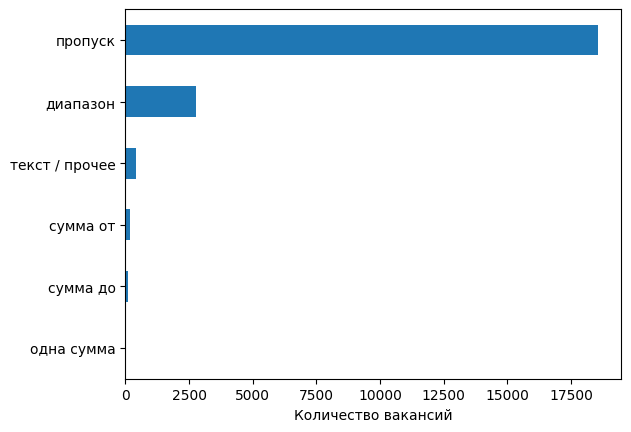

In [ ]:
salary = df["salary"].str.lower().str.split().str.join(" ")
period_re = r"(?:/\s*(?:per\s+)?|\bper\s+)(hour|hr|day|week|month|year)|(bi-weekly)"
parts = salary.str.extract(period_re)
period = parts[0].fillna(parts[1]).replace("hr", "hour")

amount = salary.str.split(period_re, n=1, regex=True).str[0]
amount = (amount.str.replace(r"^expected earnings\s*|^.*?can equal out to\s*|^.*?total compensation\s*\(", "", regex=True)
          .str.replace(r"\s*(?:commissions|depending upon|starting salary).*", "", regex=True)
          .str.replace(r"[$€,)]", "", regex=True).str.strip())
number = r"(\d+(?:\.\d+)?k?)"
pattern = rf"^(up to\s*)?{number}(?:\s*(?:-|–|to)\s*{number})?\s*(\+|/up)?$"
amounts = amount.str.extract(pattern)
amounts.columns = ["up_to", "first", "second", "plus"]

kind = pd.Series("текст / прочее", index=df.index)
kind.loc[salary.isna()] = "пропуск"
for col, label in [("first", "одна сумма"), ("plus", "сумма от"), ("second", "диапазон"), ("up_to", "сумма до")]:
    kind.loc[amounts[col].notna()] = label
display(pd.crosstab(kind, period.fillna("без периода")))
kind.value_counts().sort_values().plot.barh(xlabel="Количество вакансий")
plt.show()

Среди заполненных записей чаще всего встречается диапазон оплаты за год или за час. Есть также одиночные суммы, верхние и нижние границы. В 395 заполненных строках не удалось выделить ставку, среди них встречаются описания льгот и разовых премий.

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

,salary,salary_min,salary_max,period
13,9.00 - 13.00 $ /hour,9.00,13.00,hour
14,"80,000.00 - 95,000.00 $ /year",80000.00,95000.00,year
19,"60,000.00 - 72,000.00 $ /year",60000.00,72000.00,year
29,"70,000.00 - 100,000.00 $ /year",70000.00,100000.00,year
30,62.00 - 81.00 $ /hour,62.00,81.00,hour
32,"75,000.00 - 100,000.00 $ /year",75000.00,100000.00,year
36,"68,000.00 - 72,000.00 $ /year",68000.00,72000.00,year
41,"58,000.00 - 65,000.00 $ /year",58000.00,65000.00,year
42,Up to $32000.00,32000.00,NaN,NaN
43,15.00 - 16.00 $ /hour,15.00,16.00,hour


,count,mean,median
period,,,
bi-weekly,1,0.00,0.00
day,3,416.67,200.00
hour,1145,187.21,15.32
month,17,6048.41,4905.22
week,6,593.67,600.00
year,1755,59789.88,55000.00


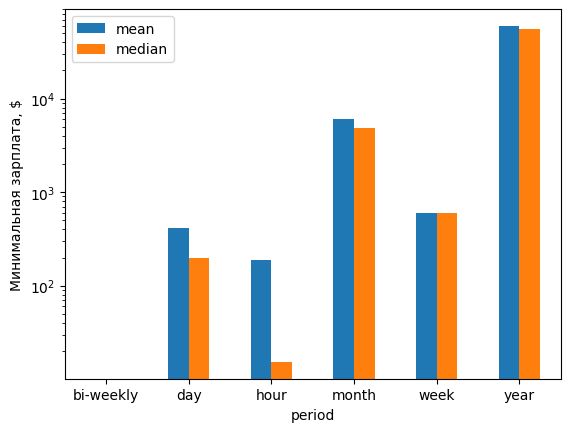

In [27]:
def to_money(s):
    multiplier = np.where(s.str.endswith("k", na=False), 1000, 1)
    return pd.to_numeric(s.str.rstrip("k")).astype(float) * multiplier

df["salary_min"] = to_money(amounts["first"])
df["salary_max"] = to_money(amounts["second"])
df["period"] = period
display(
    df.loc[df["salary_min"].notna(), ["salary", "salary_min", "salary_max", "period"]]
      .head(15)
)
usd = ~salary.str.contains("€", regex=False, na=False)
observed = df.loc[usd, ["period", "salary_min"]].dropna()
stats = observed.groupby("period")["salary_min"].agg(["count", "mean", "median"])
display(stats.round(2))
stats[["mean", "median"]].plot.bar(rot=0, logy=True, ylabel="Минимальная зарплата, $")
plt.show()

Для почасовой оплаты средняя минимальная ставка составила 187,21, а медианная - 15,32. Среднее сильно завышено отдельными высокими ставками, поэтому типичную почасовую оплату лучше описывает медиана. Для годовой оплаты разница меньше: среднее - 59 789,88, медиана - 55 000.

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

,count,min,max,mean,median
period,,,,,
bi-weekly,1,0.0,0.00,0.00,0.00
day,3,150.0,900.00,416.67,200.00
hour,1145,0.0,100000.00,187.21,15.32
month,17,1800.0,17688.94,6048.41,4905.22
week,6,12.0,1100.00,593.67,600.00
year,1755,0.0,1000000.00,59789.88,55000.00


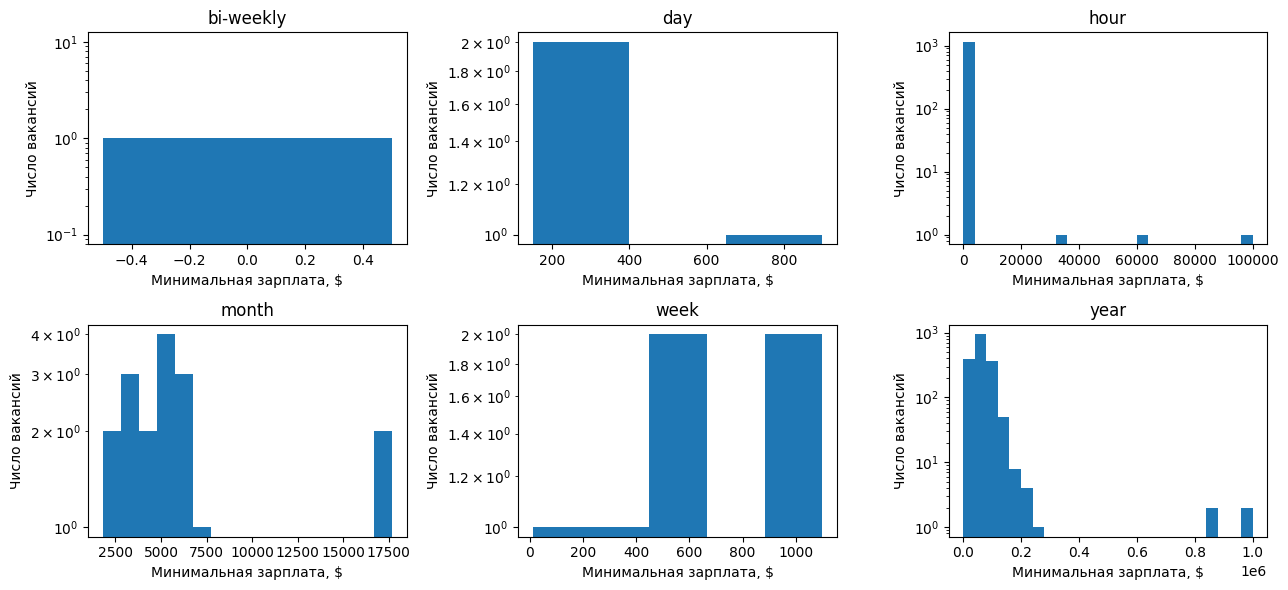

,salary,salary_min,period_filled
42,Up to $32000.00,32000.0,year
154,Up to $45000.00,45000.0,year
2424,"108,887.00 - 141,555.00",108887.0,year
2630,Up to $18.00,18.0,hour
2639,Up to $13.00,13.0,hour
2651,Up to $18.00,18.0,hour
2655,Up to $14.00,14.0,hour
2669,Up to $18.00,18.0,hour
2717,Up to $15.00,15.0,hour
2792,Up to $30000.00,30000.0,month


In [ ]:
groups = observed.groupby("period")["salary_min"]
display(groups.agg(["count", "min", "max", "mean", "median"]).round(2))
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (name, values) in zip(axes.flat, groups):
    ax.hist(values, bins=min(25, values.nunique()))
    ax.set(title=name, xlabel="Минимальная зарплата, $", ylabel="Число вакансий")
    ax.set_yscale("log")
plt.tight_layout()
plt.show()

def mean_without_outliers(values):
    values = values[values > 0]
    if len(values) >= 4:
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        values = values[values.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)]
    return values.mean()

centers = groups.apply(mean_without_outliers).dropna()

def guess_period(amount):
    distances = (centers - amount).abs()
    nearest = distances.index[np.isclose(distances, distances.min(), rtol=0, atol=1e-8)]
    return nearest[0] if len(nearest) == 1 else pd.NA

df["period_filled"] = df["period"].copy()
need = usd & df["period"].isna() & df["salary_min"].gt(0)
df.loc[need, "period_filled"] = df.loc[need, "salary_min"].map(guess_period)
display(df.loc[need, ["salary", "salary_min", "period_filled"]].head(10))

В почасовых ставках встречается значение 100 000 $ за час, которое сильно повышает среднее. Поэтому для сумм без периода использовались средние после исключения выбросов. Полученный период - приблизительная оценка. Для оплаты раз в две недели найден только один нулевой минимум, поэтому надёжного ориентира для неё нет.

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

In [ ]:
display(df["job_type"].value_counts(dropna=False).to_frame("Количество"))

,Количество
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
<NA>,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [ ]:
job = (df["job_type"].str.lower()
       .str.replace(r"^job type\s*", "", regex=True)
       .str.replace(r"[,/>]+", " ", regex=True)
       .str.replace(r"\s+", " ", regex=True)
       .str.strip().str.title())
df["job_type_clean"] = job
display(job.value_counts(dropna=False).to_frame("Количество"))

,Количество
job_type,
Full Time Employee,10538
Full Time,6773
Full Time Temporary Contract Project,1654
<NA>,1628
Part Time Employee,586
Part Time,330
Temporary Contract Project,193
Employee,148
Part Time Temporary Contract Project,57


Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

employment_type,Employee,Exempt,Intern,Seasonal,Temporary/Contract/Project
work_schedule,,,,,
Full Time,19087,1,5,0,1847
Part Time,916,0,3,17,57
Per Diem,63,0,0,0,4


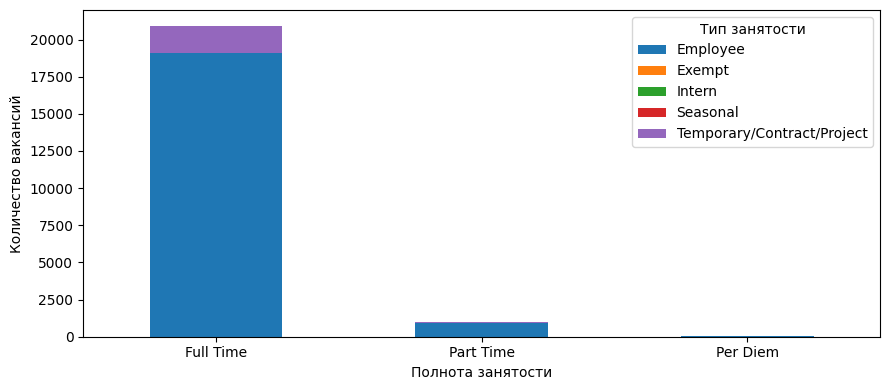

In [ ]:
schedule = job.str.extract(r"\b(Full Time|Part Time|Per Diem)\b", expand=False)
contract = job.str.extract(r"\b(Employee|Intern|Seasonal|Temporary Contract Project|Exempt)\b", expand=False)
df["work_schedule"] = schedule.fillna("Full Time")
df["employment_type"] = contract.fillna("Employee").replace("Temporary Contract Project", "Temporary/Contract/Project")
table = pd.crosstab(df["work_schedule"], df["employment_type"])
display(table)
table.plot.bar(stacked=True, rot=0, figsize=(9, 4))
plt.xlabel("Полнота занятости")
plt.ylabel("Количество вакансий")
plt.legend(title="Тип занятости", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Чаще всего встречается сочетание Full Time и Employee. Его численность зависит от правила заполнения пропусков, к этой группе отнесены в том числе 1 628 вакансий, в которых поле job_type было полностью пустым.

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.